- To look at basic QC metrics

- To refine annoations of cell subtypes (based on Azimuth predicted.celltype.l2) by calc DEGs (and check with literature markers), and by mapping from ref CD4 T dataset (because it is more refined)

Found out:
1. Results do not change much re-running Azimuth - it is actually not getting better as it predicts platelets within B cells, indicating that using global reference is not optimal when running within single major cell types. Thus using original Azimuth annotation
2. Re-examine per doublet status - re-ran scrublet-R, and excluded some doublets - it turned out this re-run is not with better results (ie, to distinguish doublet clusters) - b/c previous runs are within single sample and current is within one major cell type across single samples thus affected by batch effect. Thus Thus using original scrublet annotation

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'DC'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 8634 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

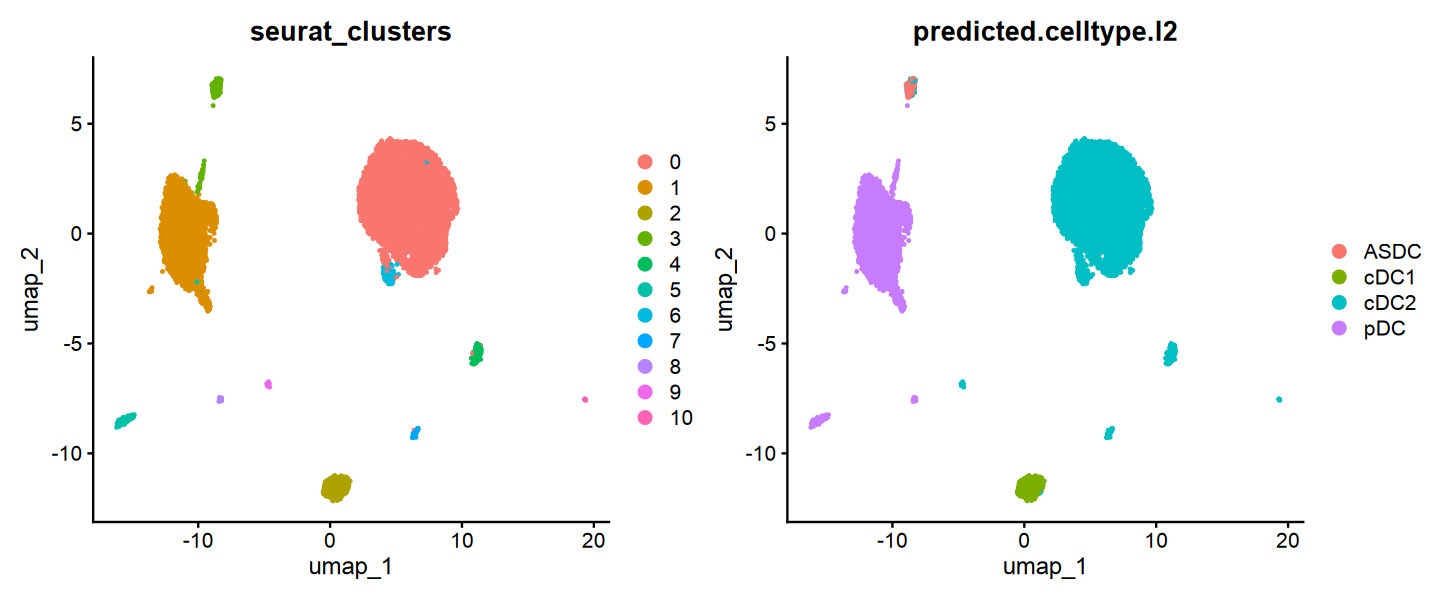

In [9]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

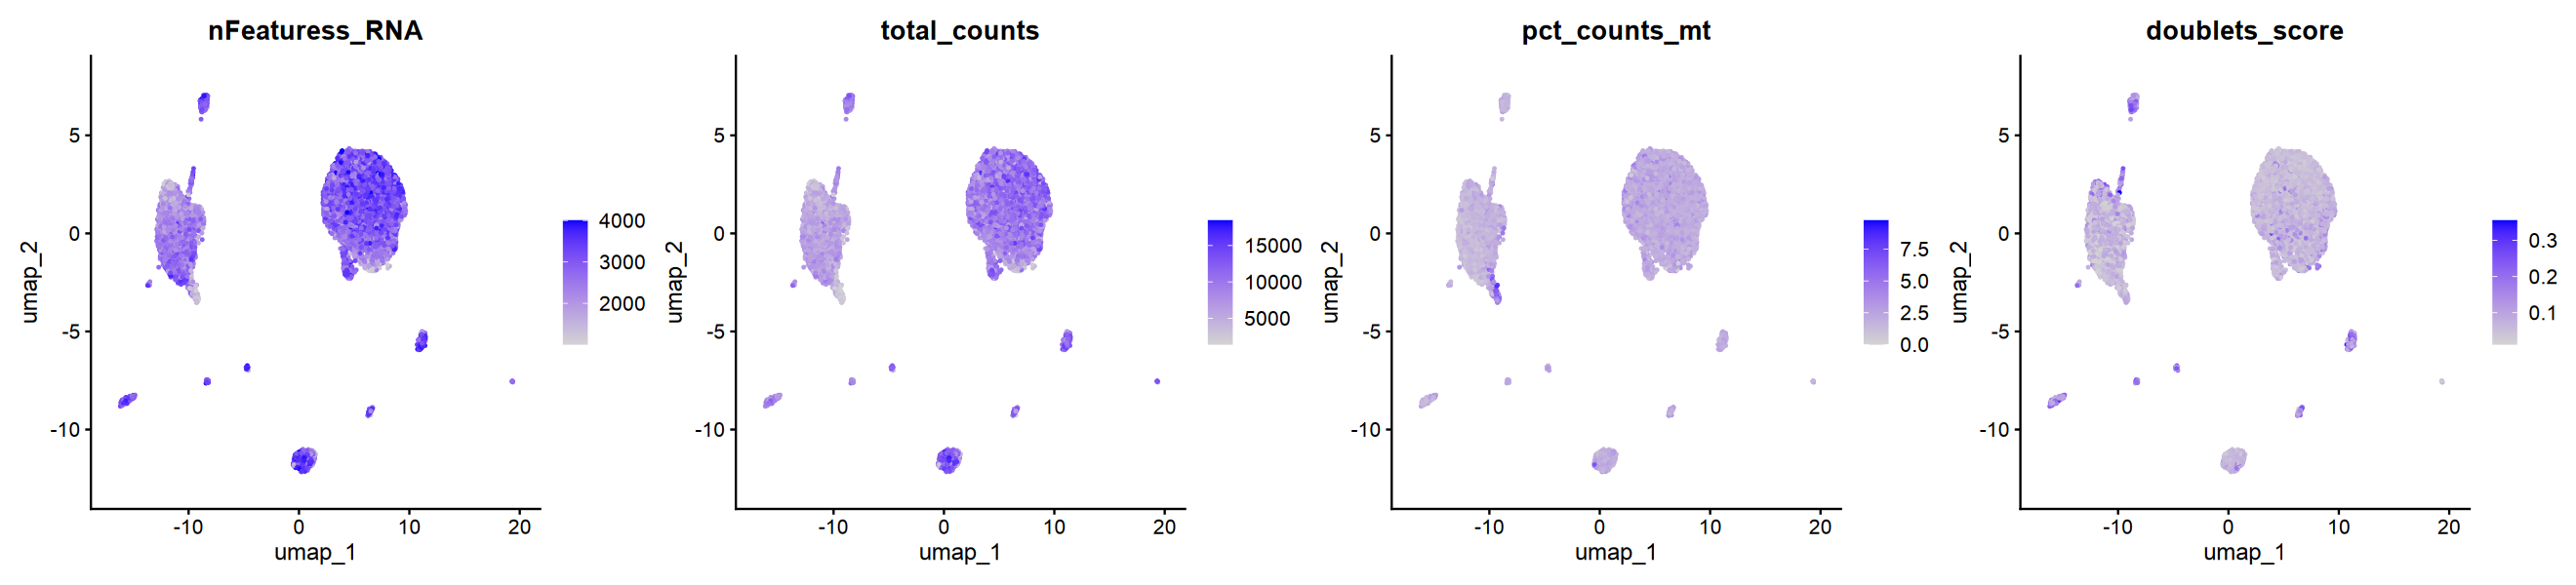

In [10]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

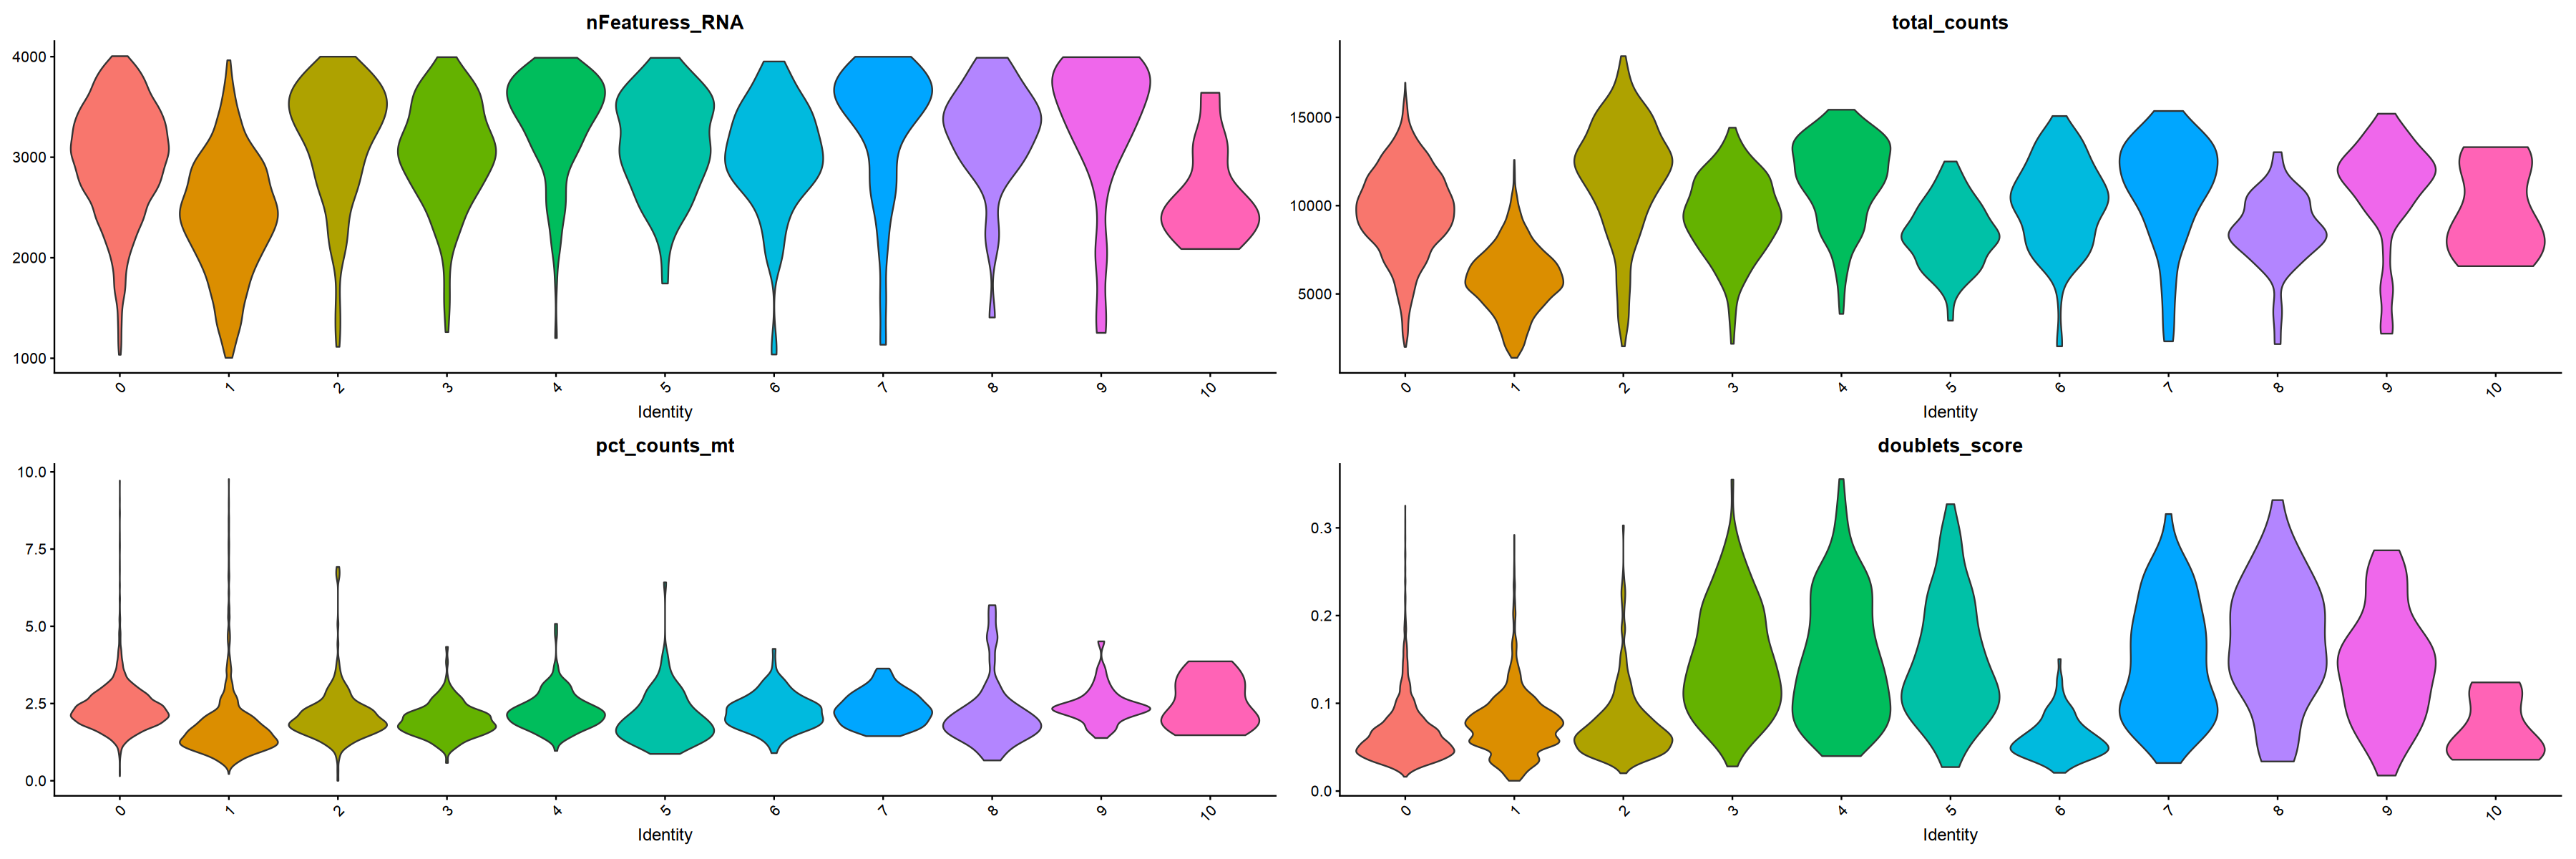

In [13]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

In [22]:
# cluster 4 and 10 are likely doublets
# we filter them and redo clustering

ft = subset(x = obj, 
            subset = !(seurat_clusters %in% c(3,4,5, 7,8,9,10)))

ft

An object of class Seurat 
28202 features across 8012 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

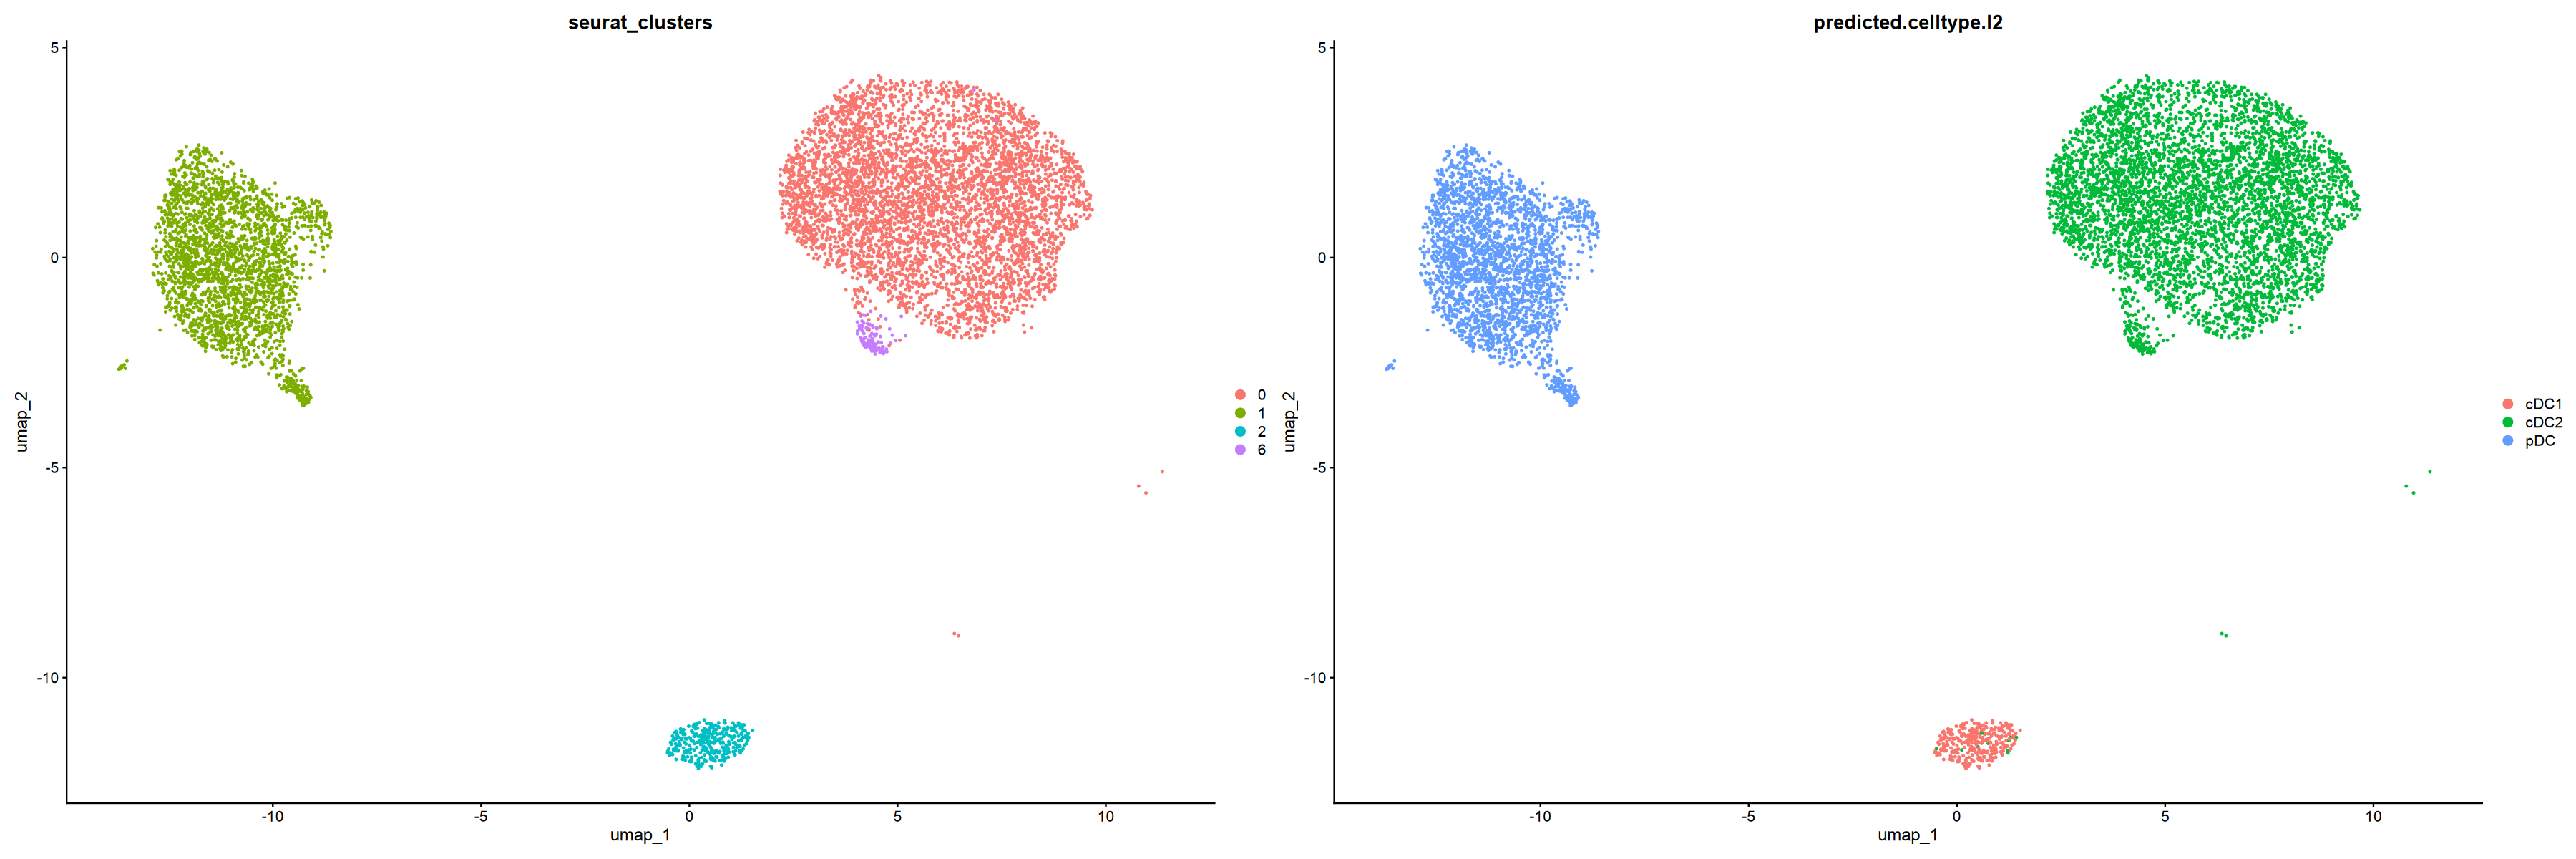

In [23]:
DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

In [24]:
ft <- FindNeighbors(ft, dims = 1:30, reduction = "harmony")
ft <- RunUMAP(ft, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN

14:44:42 UMAP embedding parameters a = 0.9922 b = 1.112

14:44:42 Read 8012 rows and found 30 numeric columns

14:44:42 Using Annoy for neighbor search, n_neighbors = 30

14:44:42 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:44:44 Writing NN index file to temp file /tmp/Rtmpb57m4y/file5cb564c5592bc

14:44:44 Searching Annoy index using 1 thread, search_k = 3000

14:44:46 Annoy recall = 100%

14:44:47 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:44:48 Found 2 connected components, 
falling back to 'spca' initialization with init_sdev = 1

14:44:48 Using 'irlba' for PCA

14:44:48 PCA: 2 components explained 72.51% variance

14:44:48 Scaling init to sdev = 1

14:44:48 Com

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 8012
Number of edges: 317573

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8854
Number of communities: 6
Elapsed time: 1 seconds


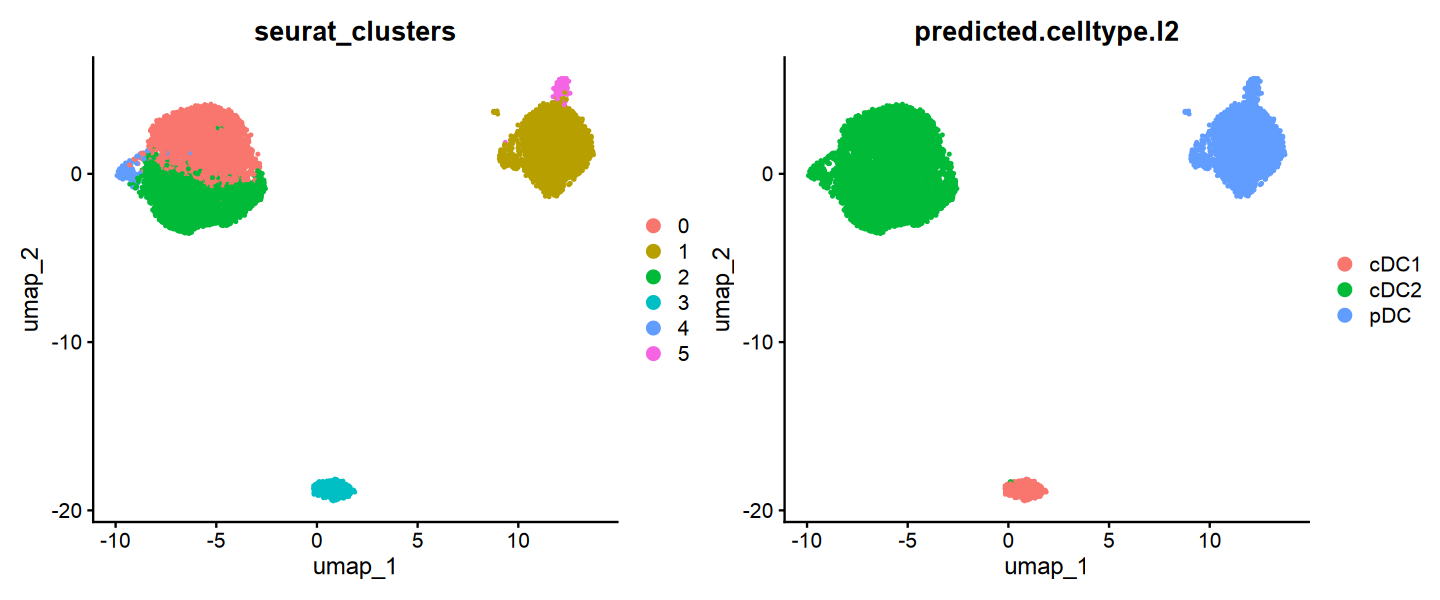

In [25]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

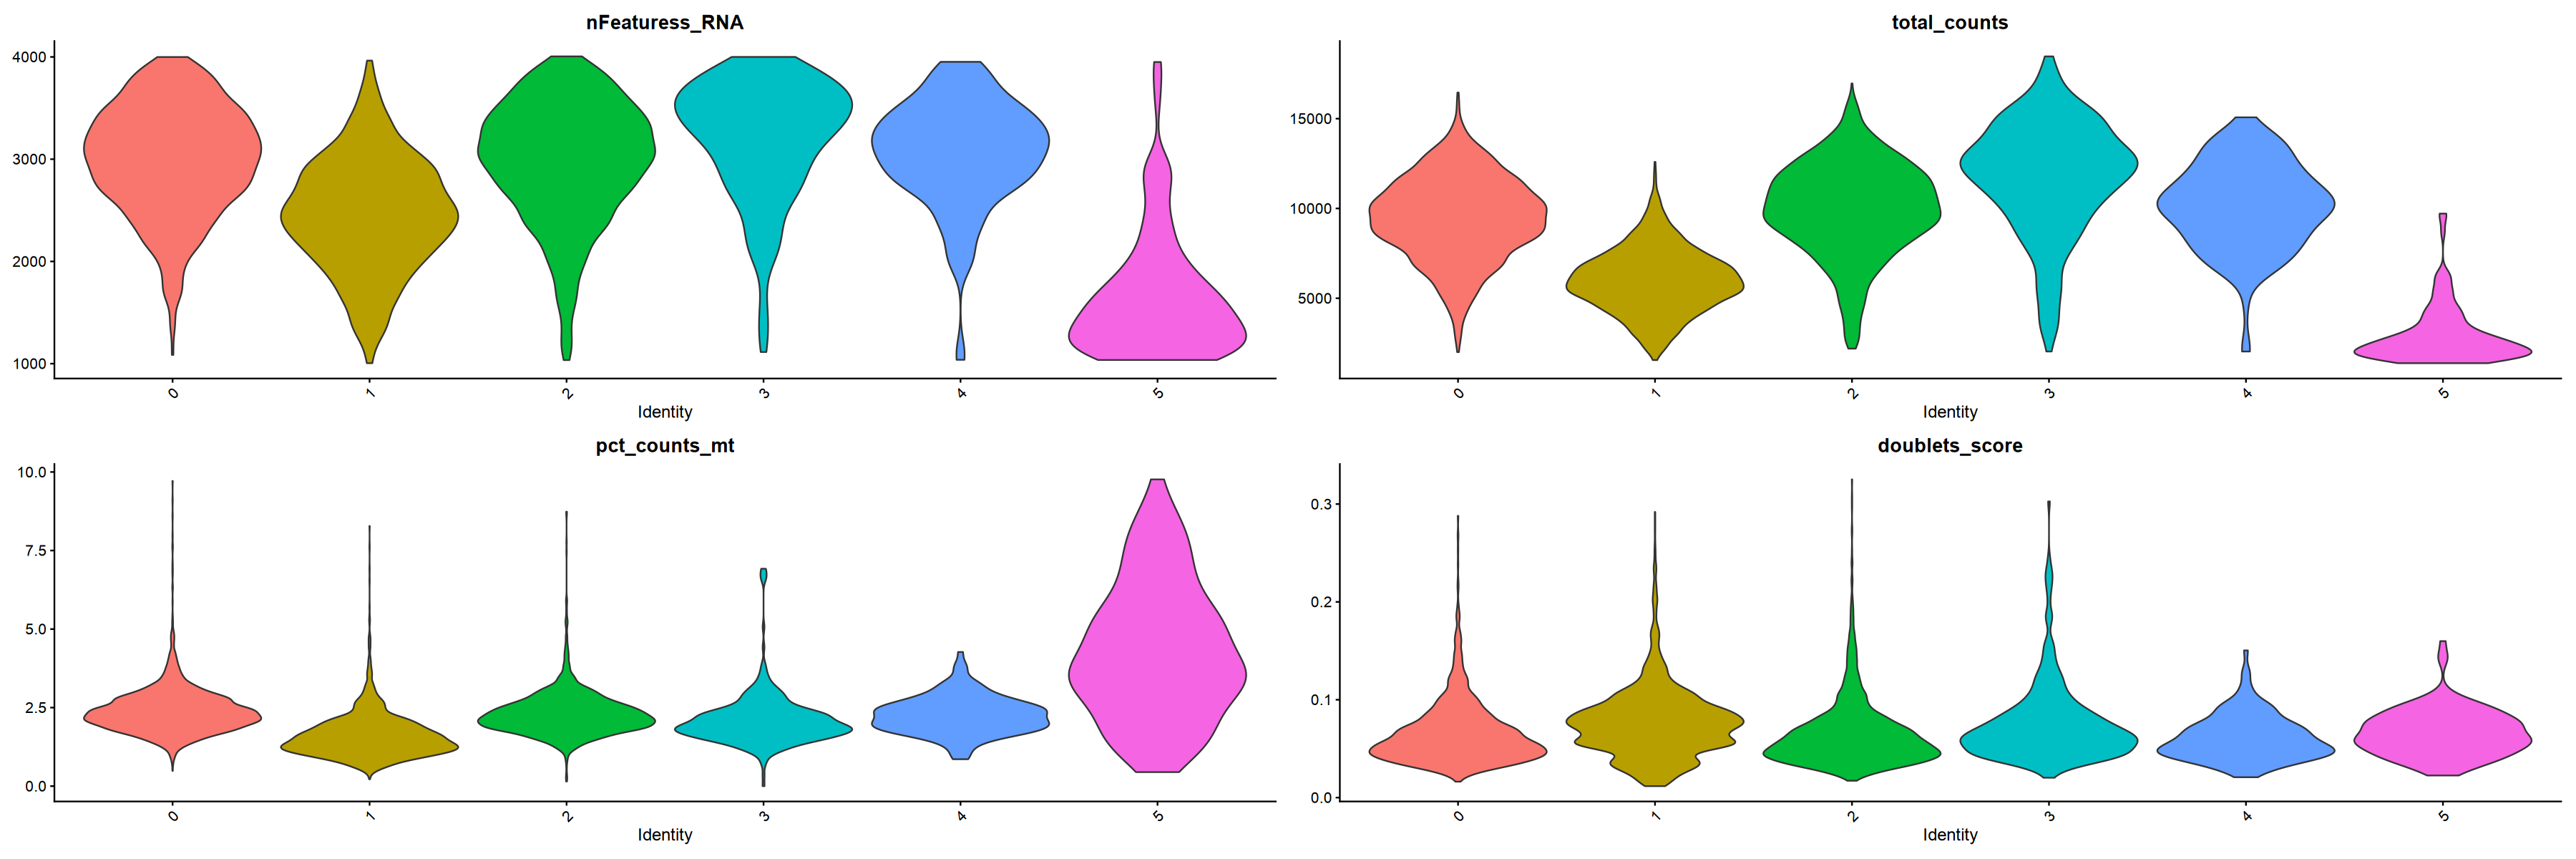

In [26]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

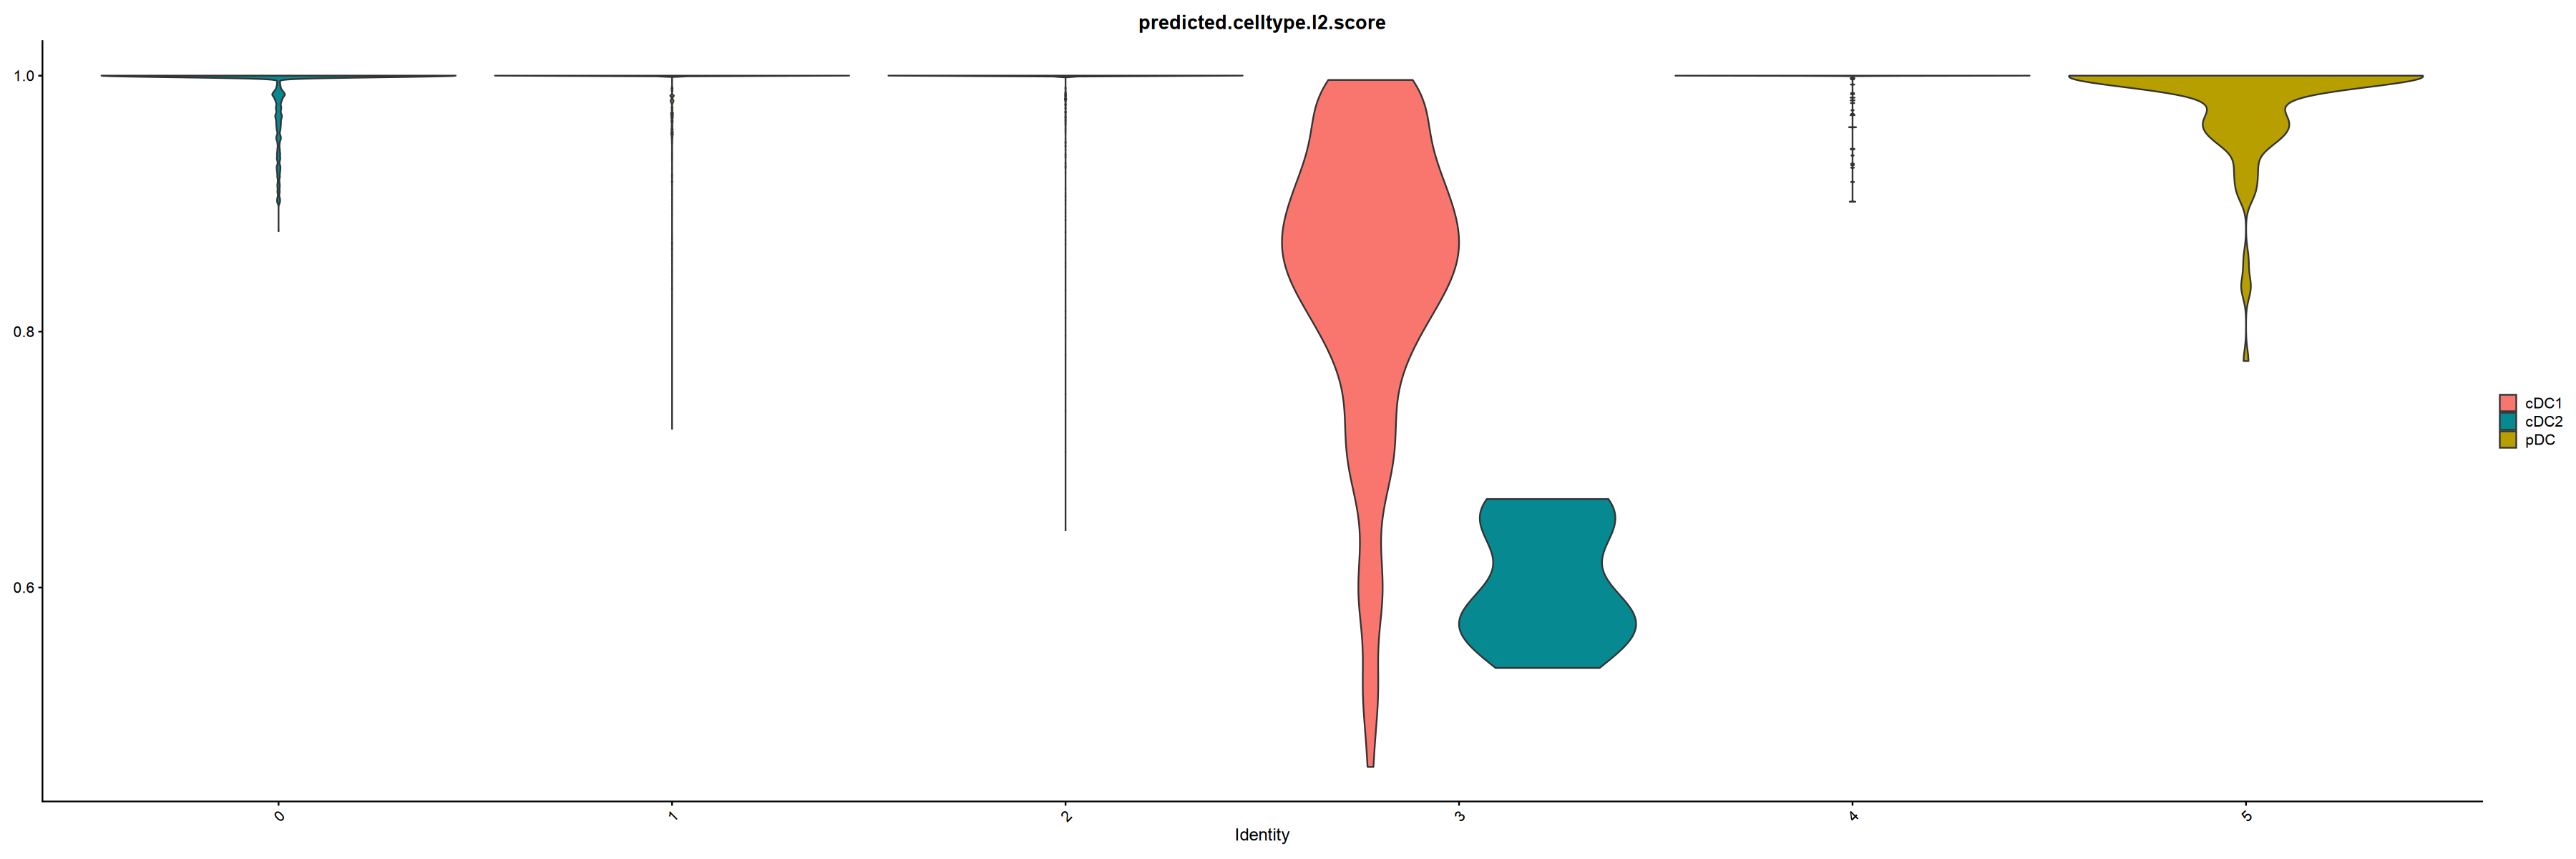

In [27]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [28]:
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,cDC1,cDC2,pDC
,<dbl>,<dbl>,<dbl>
0,0.00000,100.000000,0
1,0.00000,0.000000,100
2,0.00000,100.000000,0
3,96.51163,3.488372,0
4,0.00000,100.000000,0
5,0.00000,0.000000,100


In [29]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 70]) )
print(clusters_low_purity)

integer(0)


In [30]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- setdiff(as.integer(rownames(ctab)), clusters_low_purity)

meta_tmp <- ft@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno1 = meta_tmp %>% drop_na()
dim(anno1)                       
head(anno1  )   

[1] 8012    2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGGTTGGTGGA-1,2,cDC2
Pool137_10_AAAGTAGCAGGGATTG-1,4,cDC2
Pool137_10_AACCATGAGTGTTTGC-1,2,cDC2
Pool137_10_AACCGCGCATACCATG-1,2,cDC2
Pool137_10_AACCGCGGTAAATGTG-1,2,cDC2
Pool137_10_AACCGCGTCCGAGCCA-1,0,cDC2


In [31]:
anno = anno1

anno = anno[Cells(ft),]

dim(anno)
head(anno)

[1] 8012    2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGGTTGGTGGA-1,2,cDC2
Pool137_10_AAAGTAGCAGGGATTG-1,4,cDC2
Pool137_10_AACCATGAGTGTTTGC-1,2,cDC2
Pool137_10_AACCGCGCATACCATG-1,2,cDC2
Pool137_10_AACCGCGGTAAATGTG-1,2,cDC2
Pool137_10_AACCGCGTCCGAGCCA-1,0,cDC2


In [32]:
ft = AddMetaData(ft, 
                 metadata = anno$celltype_level3, 
                 col.name = "celltype_level3")

In [33]:
table(ft@meta.data$celltype_level3)


cDC1 cDC2  pDC 
 344 5113 2555 

## Save

In [34]:
map <- c(
  "cDC1" = "cDC1",
  "cDC2" = "cDC2",
  "pDC" = "pDC"
)

# Map values
ft@meta.data[['celltype_level3']] <- map[ ft@meta.data[['celltype_level3']] ]

In [35]:
cell_ordered = c(
    "cDC1",
    "cDC2",
    "pDC"

)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [36]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

# Visualize

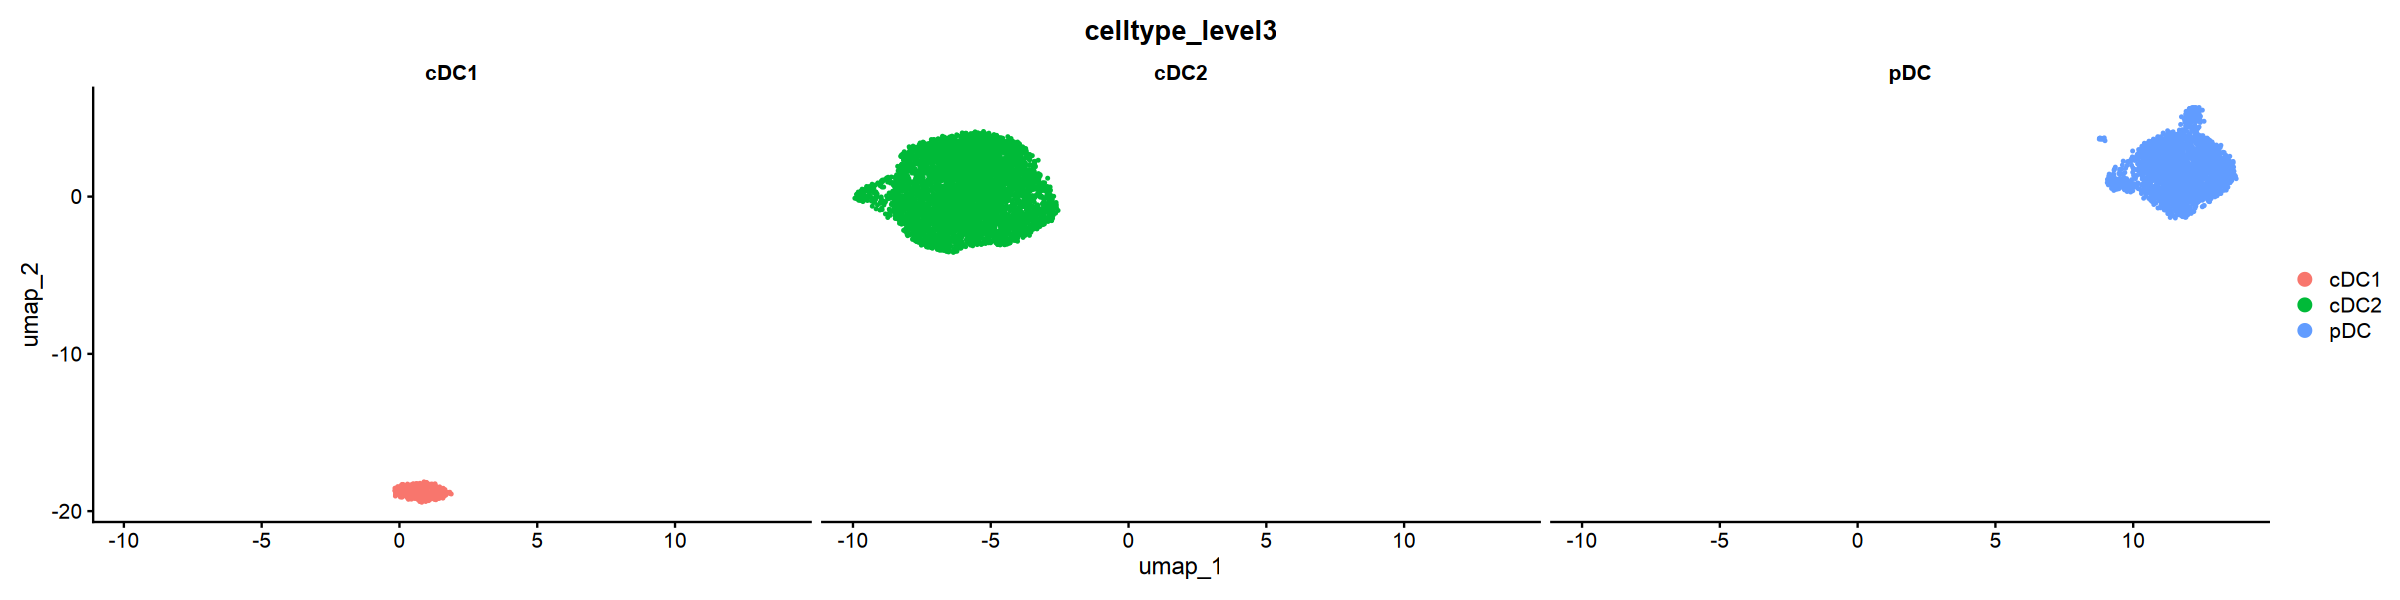

In [37]:
options(repr.plot.width=20, repr.plot.height=5)

varname = 'celltype_level3'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

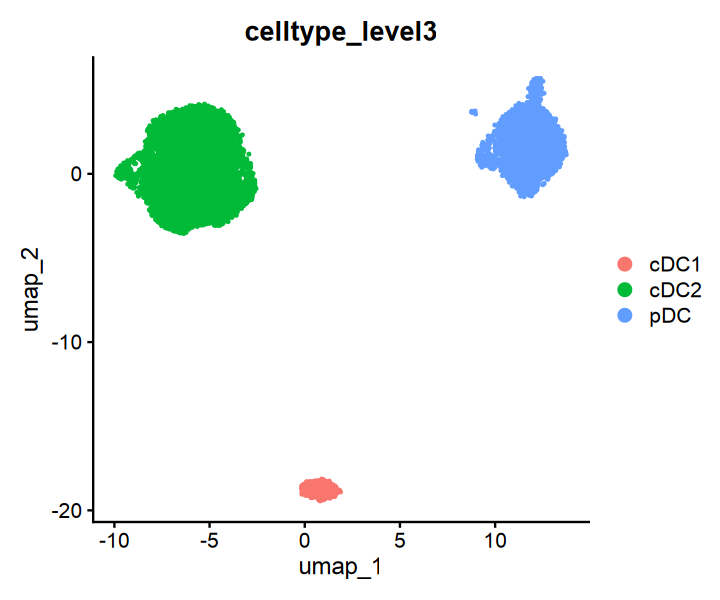

In [38]:
options(repr.plot.width=6, repr.plot.height=5)

DimPlot(ft, reduction = "umap", group.by='celltype_level3')

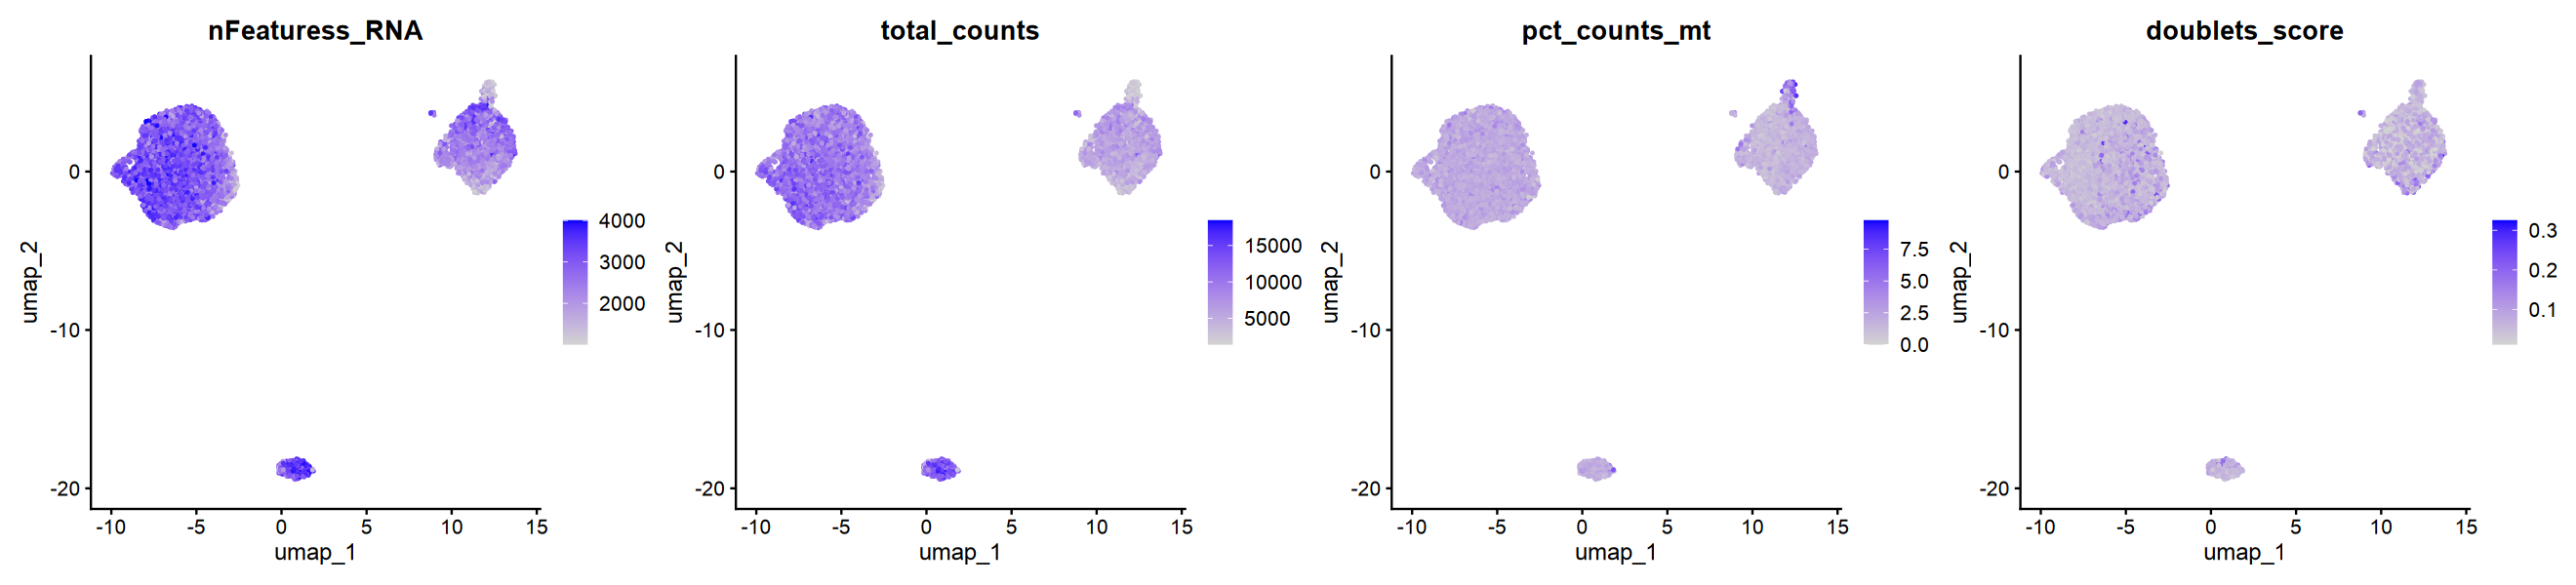

In [39]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(ft, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

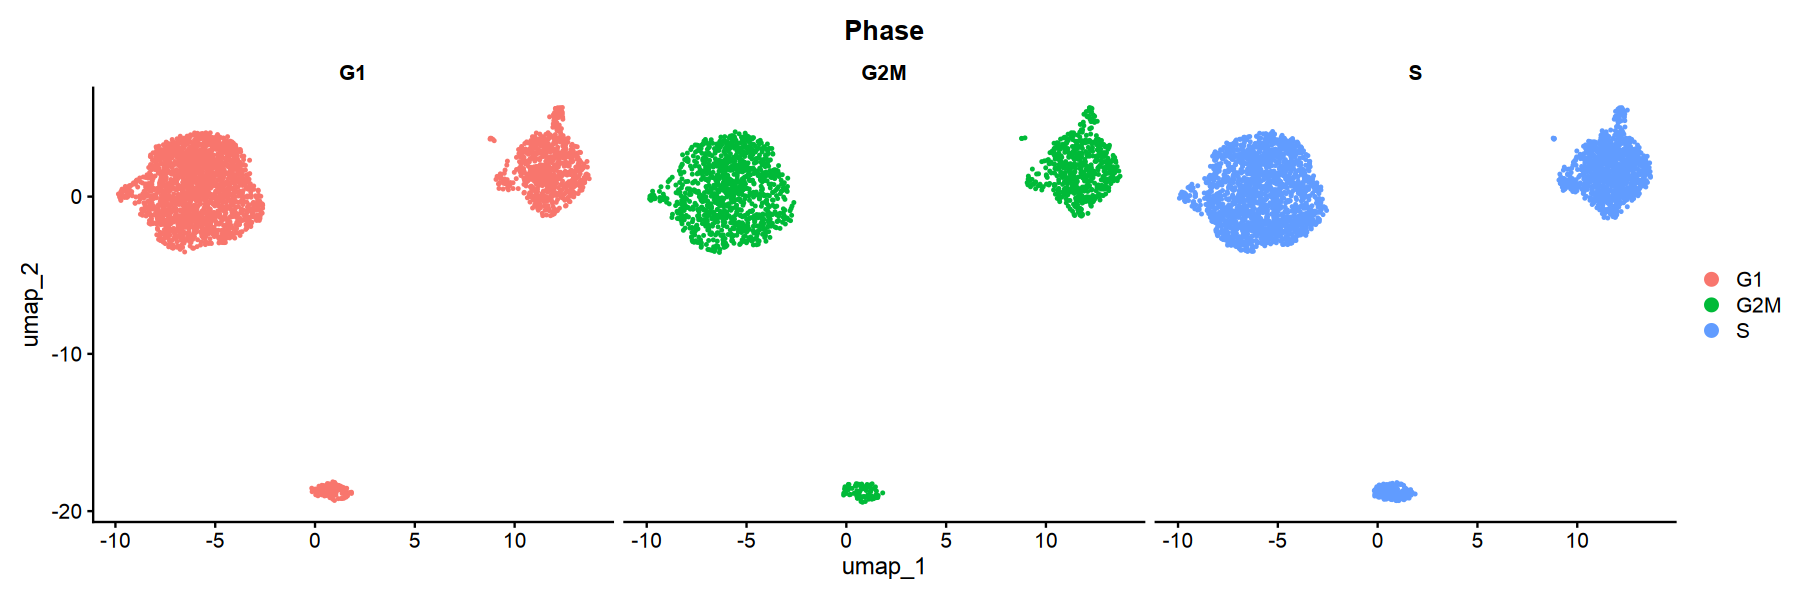

In [40]:
options(repr.plot.width=15, repr.plot.height=5)
varname = 'Phase'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [41]:
length(unique(ft@meta.data$dataset_name))

[1] 56

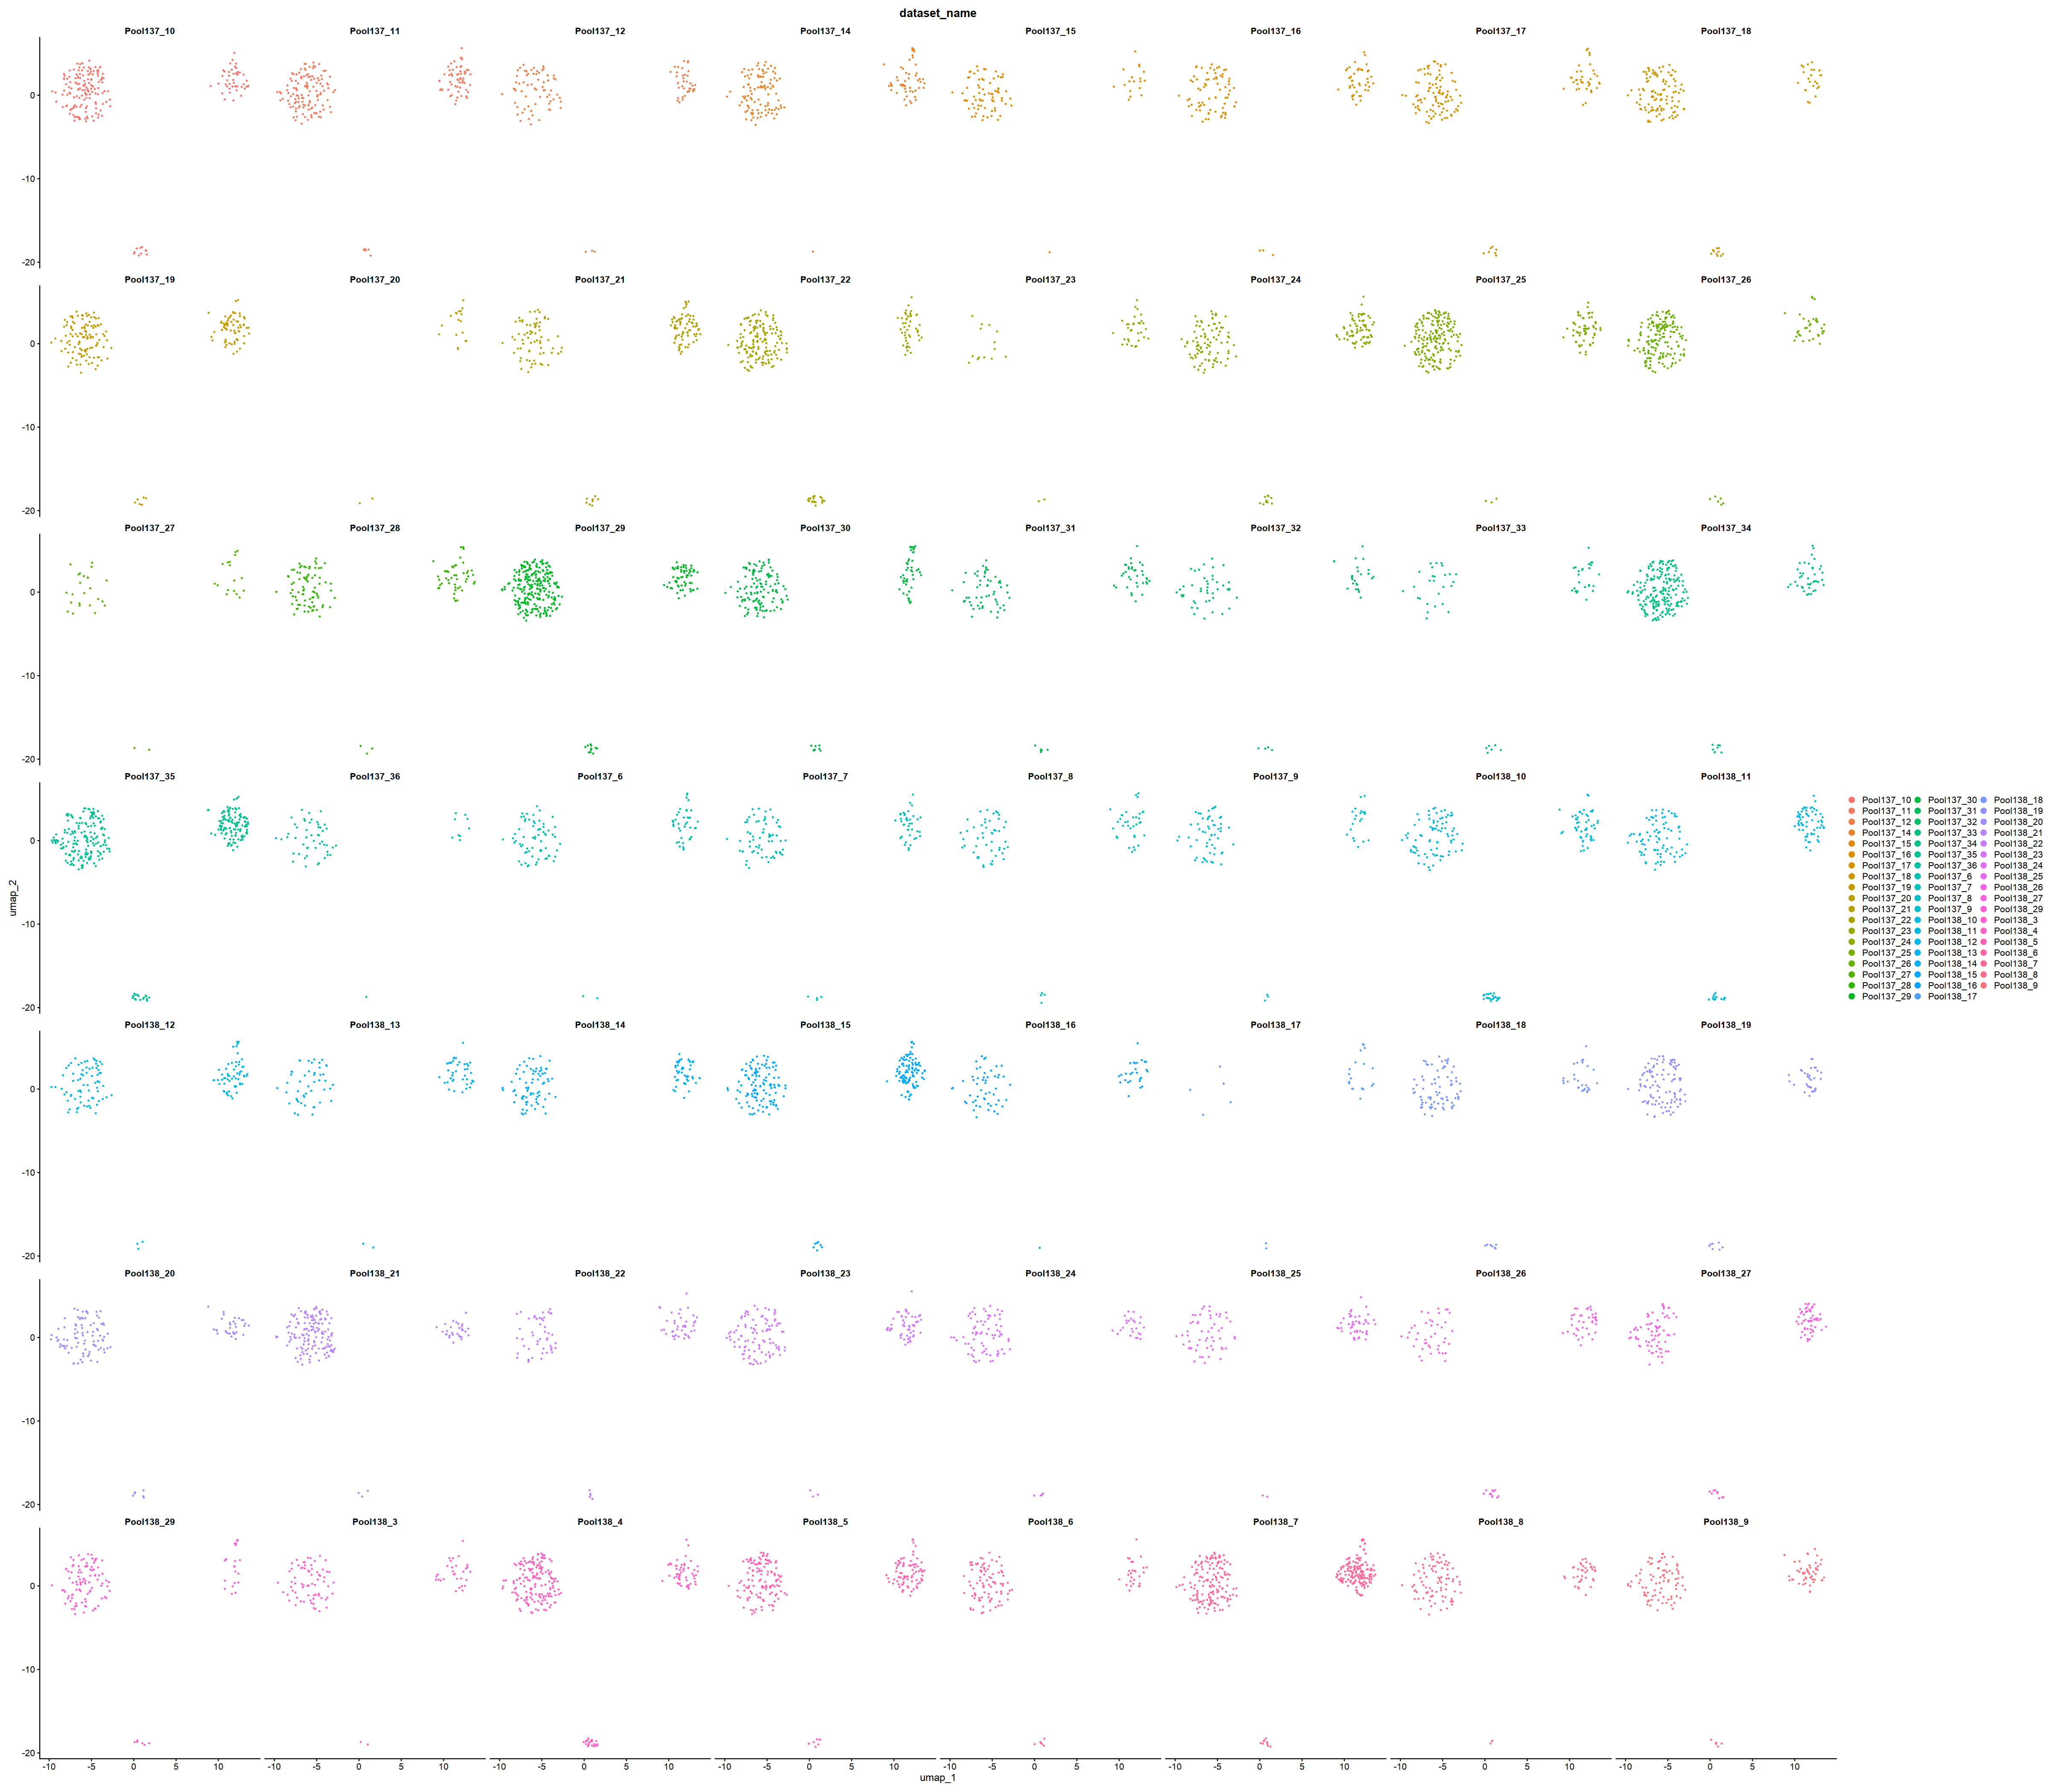

In [42]:
options(repr.plot.width=40, repr.plot.height=35)

varname = 'dataset_name'
DimPlot(ft, reduction = "umap",  
        ncol = 8,
        group.by = varname,
        split.by = varname)

# DEGs

In [43]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster cDC1

Calculating cluster cDC2

Calculating cluster pDC



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CLEC9A,0,8.651170,0.959,0.011,0,cDC1,CLEC9A
C1orf54,0,5.507991,0.971,0.083,0,cDC1,C1orf54
CLNK,0,6.264695,0.919,0.034,0,cDC1,CLNK
CADM1,0,9.504532,0.814,0.002,0,cDC1,CADM1
IDO1,0,6.554316,0.762,0.023,0,cDC1,IDO1
TMEM14A,0,3.411946,0.701,0.067,0,cDC1,TMEM14A


In [44]:
write.csv(markers, 
          glue('data/04_markergenes/{celltype}.csv'))

In [45]:
markers = read.csv(glue('data/04_markergenes/{celltype}.csv'),
                   row.names=1
                  )

cell_ordered = c(
    "cDC1",
    "cDC2",
    "pDC"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)


In [46]:
markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 10) %>%
    ungroup() -> top10

top10

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,8.651170,0.959,0.011,0,cDC1,CLEC9A
0,5.507991,0.971,0.083,0,cDC1,C1orf54
0,6.264695,0.919,0.034,0,cDC1,CLNK
0,9.504532,0.814,0.002,0,cDC1,CADM1
0,6.554316,0.762,0.023,0,cDC1,IDO1
0,3.411946,0.701,0.067,0,cDC1,TMEM14A
0,4.403870,0.677,0.053,0,cDC1,NCALD
0,3.888986,0.680,0.065,0,cDC1,SLC24A4
0,4.506699,0.634,0.034,0,cDC1,C1orf21


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


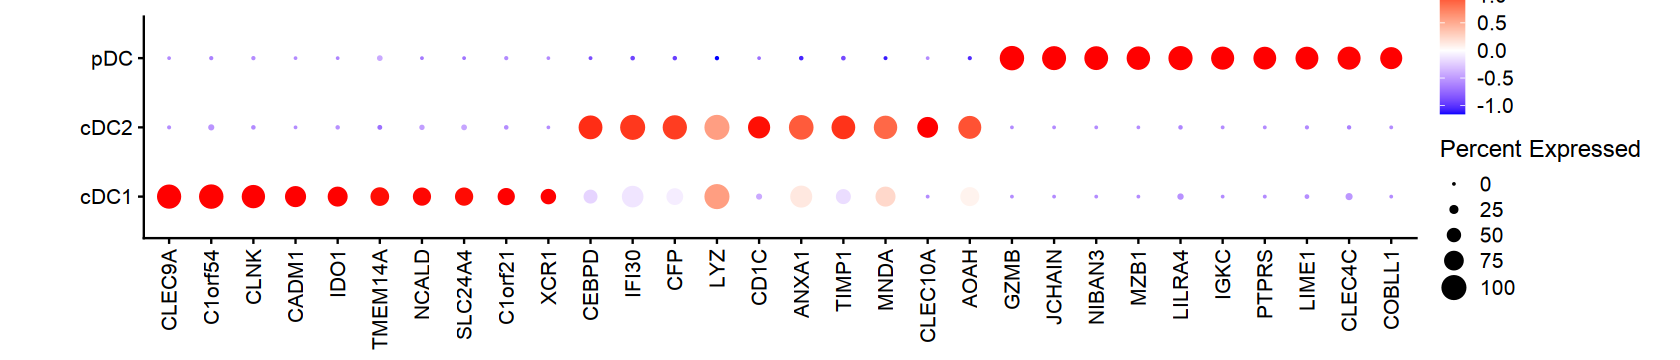

In [47]:
options(repr.plot.width=14, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = unique(unlist(top10$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )


print(p)

In [48]:
marker_azi = read.csv('data/04_markergenes/azimuth_markers.csv')
marker_azi

Level,Label,Expanded.Label,OBO.Ontology.ID,Markers
<int>,<chr>,<chr>,<chr>,<chr>
1,Mono,Monocyte,monocyte,"CTSS, FCN1, NEAT1, LYZ, PSAP, S100A9, AIF1, MNDA, SERPINA1, TYROBP"
1,CD4 T,CD4+ T cell,"CD4-positive, alpha-beta T cell","IL7R, MAL, LTB, CD4, LDHB, TPT1, TRAC, TMSB10, CD3D, CD3G"
1,CD8 T,CD8+ T cell,"CD8-positive, alpha-beta T cell","CD8B, CD8A, CD3D, TMSB10, HCST, CD3G, LINC02446, CTSW, CD3E, TRAC"
1,NK,natural killer cell,natural killer cell,"NKG7, KLRD1, TYROBP, GNLY, FCER1G, PRF1, CD247, KLRF1, CST7, GZMB"
1,B,B cell,mature B cell,"CD79A, RALGPS2, CD79B, MS4A1, BANK1, CD74, TNFRSF13C, HLA-DQA1, IGHM, MEF2C"
1,other T,other T cell,mature T cell,"CD3D, TRDC, GZMK, KLRB1, NKG7, TRGC2, CST7, LYAR, KLRG1, GZMA"
1,DC,dendritic cell,dendritic cell,"CD74, HLA-DPA1, HLA-DPB1, HLA-DQA1, CCDC88A, HLA-DRA, HLA-DMA, CST3, HLA-DQB1, HLA-DRB1"
2,B intermediate,Intermediate B cell,mature B cell,"MS4A1, TNFRSF13B, IGHM, IGHD, AIM2, CD79A, LINC01857, RALGPS2, BANK1, CD79B"
2,B memory,Memory B cell,memory B cell,"MS4A1, COCH, AIM2, BANK1, SSPN, CD79A, TEX9, RALGPS2, TNFRSF13C, LINC01781"


In [49]:
names_sel <- c(

    "cDC1",
    "cDC2",
    "pDC"
    )  # <- your cell types of interest

# Filter marker_azi for the selected labels
marker_df <- marker_azi %>% 
filter(Level == 2) %>%
filter(Label %in% names_sel)

# Split the comma-separated Markers into list elements, assign names
markers <- setNames(
  strsplit(marker_df$Markers, ",\\s*"),   # split each marker by comma + space
  marker_df$Label
)

markers

$cDC1
 [1] "CLEC9A"   "DNASE1L3" "C1orf54"  "IDO1"     "CLNK"     "CADM1"   
 [7] "FLT3"     "ENPP1"    "XCR1"     "NDRG2"   

$cDC2
 [1] "FCER1A"   "HLA-DQA1" "CLEC10A"  "CD1C"     "ENHO"     "PLD4"    
 [7] "GSN"      "SLC38A1"  "NDRG2"    "AFF3"    

$pDC
 [1] "ITM2C"    "PLD4"     "SERPINF1" "LILRA4"   "IL3RA"    "TPM2"    
 [7] "MZB1"     "SPIB"     "IRF4"     "SMPD3"

In [51]:
# Set your desired cell type order:
type_order <- names_sel

# Unlist markers in that order, dropping duplicates but preserving order:
features_to_plot <- unlist(markers[type_order], use.names = FALSE)
features_to_plot <- features_to_plot[!duplicated(features_to_plot)]  # Remove duplicates, keep order

# Optionally, keep only genes present in your Seurat object:
features_to_plot <- features_to_plot[features_to_plot %in% rownames(ft)]
features_to_plot

[1] "CLEC9A"   "DNASE1L3" "C1orf54"  "IDO1"     "CLNK"     "CADM1"   
 [7] "FLT3"     "ENPP1"    "XCR1"     "NDRG2"    "FCER1A"   "HLA-DQA1"
[13] "CLEC10A"  "CD1C"     "ENHO"     "PLD4"     "GSN"      "SLC38A1" 
[19] "AFF3"     "ITM2C"    "SERPINF1" "LILRA4"   "IL3RA"    "TPM2"    
[25] "MZB1"     "SPIB"     "IRF4"     "SMPD3"

Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


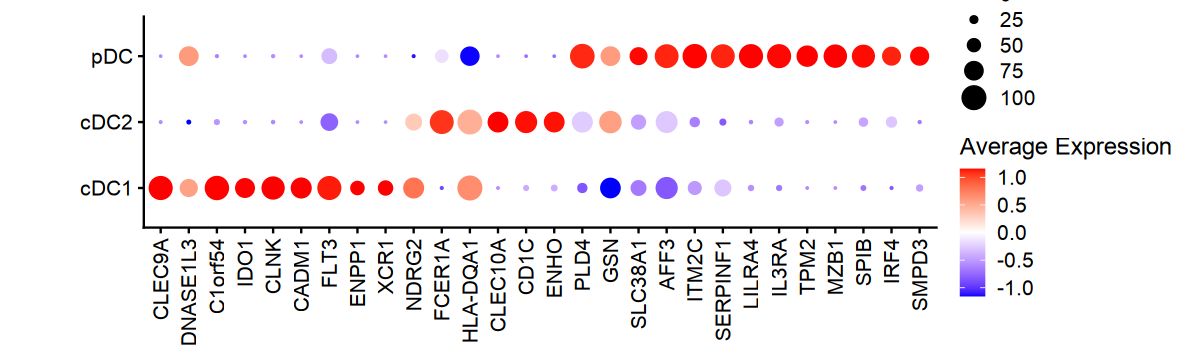

In [52]:
options(repr.plot.width=10, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = features_to_plot,
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )

print(p)

# MS4A1''TNFRSF13B''IGHM''IGHD''AIM2''CD79A''LINC01857''RALGPS2''BANK1''CD79B'

Warning message in DoHeatmap(subset(ft, downsample = 100), features = features_to_plot, :
“The following features were omitted as they were not found in the scale.data slot for the RNA assay: SLC38A1, GSN”


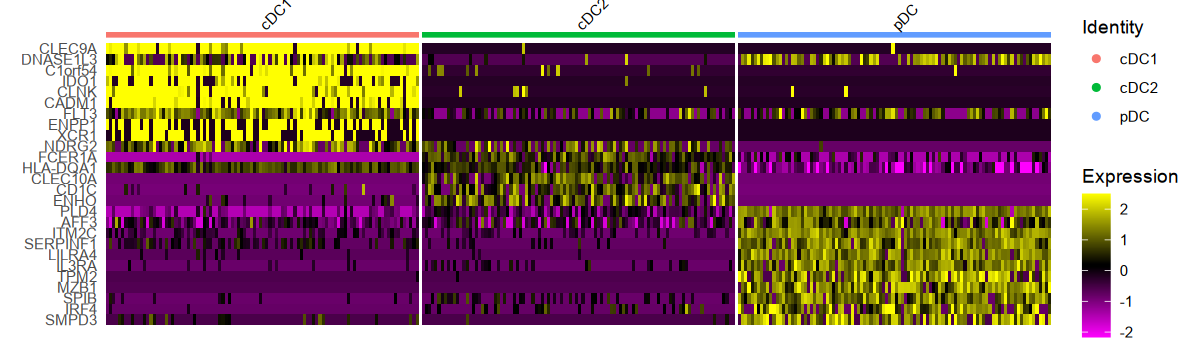

In [53]:
Idents(ft) =  "celltype_level3"

DoHeatmap(subset(ft, downsample = 100), 
          features = features_to_plot, size = 3)